In [1]:
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from typing import TypedDict,Annotated,Any
from langchain.chat_models import init_chat_model
from langchain_core.messages import BaseMessage,SystemMessage,HumanMessage
import requests
import math
from langgraph.prebuilt import tools_condition,ToolNode
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS


In [2]:
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [3]:
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
import os
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [5]:
model=ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.5,
    max_tokens=None,
    timeout=None,
    max_retries=2,
)

embedding_model=GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001",
)

In [10]:
loader=PyPDFLoader("attention.pdf")
docs=loader.load()
len(docs)

15

In [11]:
splitter=RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
)
chunks=splitter.split_documents(docs)
len(chunks)

52

In [12]:
vector_store=FAISS.from_documents(
    documents=chunks,
    embedding=embedding_model
)

In [13]:
retriever=vector_store.as_retriever(
    search_type='similarity',
    search_kwargs={"k":4}
)

In [21]:
retriever.invoke("using the pdf notes,explain about transformer in a concise manner")

[Document(id='accf470d-3c7f-438c-8fb9-e3448c8d40a4', metadata={'producer': 'pdfTeX-1.40.25', 'creator': 'LaTeX with hyperref', 'creationdate': '2024-04-10T21:11:43+00:00', 'author': '', 'keywords': '', 'moddate': '2024-04-10T21:11:43+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.25 (TeX Live 2023) kpathsea version 6.3.5', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'attention.pdf', 'total_pages': 15, 'page': 2, 'page_label': '3'}, page_content='Figure 1: The Transformer - model architecture.\nThe Transformer follows this overall architecture using stacked self-attention and point-wise, fully\nconnected layers for both the encoder and decoder, shown in the left and right halves of Figure 1,\nrespectively.\n3.1 Encoder and Decoder Stacks\nEncoder: The encoder is composed of a stack of N = 6 identical layers. Each layer has two\nsub-layers. The first is a multi-head self-attention mechanism, and the second is a simple, position-\nwise fully connec

In [14]:
# Tools
web_search_tool=TavilySearch(
    max_results=5,
    topic="general",
    search_depth="advanced"
)

@tool
def calculator(expression: str) -> str:
    """
    Useful for simple math calculations.
    Input should be a valid math expression.
    Example: 2 + 2, math.sqrt(16), 10 * 5
    """

    try:
        allowed = {
            "math": math,
            "abs": abs,
            "round": round,
            "min": min,
            "max": max,
            "sum": sum
        }

        result = eval(expression, {"__builtins__": {}}, allowed)
        return str(result)

    except Exception as e:
        return f"Calculation error: {str(e)}"

@tool
def get_stock_price(company:str)->dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA') 
    using Alpha Vantage with API key in the URL.
    """
    url = f'https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={company}&interval=5min&apikey=R0LOZRN8U0ENG0C0'
    r = requests.get(url)
    return r.json()



@tool
def get_current_weather(location: str) -> str:
    """
    Get current weather for a city or location.

    Args:
        location: City name, e.g. Hyderabad, London, UK.
    """
    api_key = os.getenv("OPENWEATHER_API_KEY")

    if not api_key:
        return "Error: OPENWEATHER_API_KEY environment variable is missing."

    try:
        # Step 1: Convert location into latitude and longitude
        geo_url = "https://api.openweathermap.org/geo/1.0/direct"

        geo_response = requests.get(
            geo_url,
            params={
                "q": location,
                "limit": 1,
                "appid": api_key,
            },
            timeout=10,
        )
        geo_response.raise_for_status()

        locations: list[dict[str, Any]] = geo_response.json()

        if not locations:
            return f"Could not find location: {location}"

        latitude = locations[0]["lat"]
        longitude = locations[0]["lon"]

        city = locations[0].get("name", location)
        state = locations[0].get("state", "")
        country = locations[0].get("country", "")

        display_location = ", ".join(
            part for part in [city, state, country] if part
        )

        # Step 2: Fetch current weather using coordinates
        weather_url = "https://api.openweathermap.org/data/2.5/weather"

        weather_response = requests.get(
            weather_url,
            params={
                "lat": latitude,
                "lon": longitude,
                "appid": api_key,
                "units": "metric",
            },
            timeout=10,
        )
        weather_response.raise_for_status()

        data = weather_response.json()

        # Step 3: Extract weather information
        temperature = data["main"]["temp"]
        feels_like = data["main"]["feels_like"]
        humidity = data["main"]["humidity"]
        pressure = data["main"]["pressure"]
        description = data["weather"][0]["description"]
        wind_speed = data.get("wind", {}).get("speed", "N/A")

        visibility_meters = data.get("visibility")
        visibility_km = (
            round(visibility_meters / 1000, 1)
            if visibility_meters is not None
            else "N/A"
        )

        # Step 4: Format the result
        return (
            f"Current weather in {display_location}:\n"
            f"- Condition: {description.title()}\n"
            f"- Temperature: {temperature}°C\n"
            f"- Feels like: {feels_like}°C\n"
            f"- Humidity: {humidity}%\n"
            f"- Pressure: {pressure} hPa\n"
            f"- Wind speed: {wind_speed} m/s\n"
            f"- Visibility: {visibility_km} km"
        )

    except requests.exceptions.Timeout:
        return "Error: Weather service request timed out."

    except requests.exceptions.HTTPError as error:
        status = error.response.status_code if error.response else 0

        if status == 401:
            return "Error: Invalid or inactive OpenWeather API key."
        if status == 404:
            return f"Error: Weather data not found for {location}."
        if status == 429:
            return "Error: OpenWeather API rate limit exceeded."

        return f"Error: OpenWeather API returned HTTP {status}."

    except requests.exceptions.RequestException:
        return "Error: Could not connect to the OpenWeather service."

    except (KeyError, IndexError, TypeError, ValueError):
        return "Error: Unexpected or invalid weather API response."


@tool
def rag_tool(query: str) -> str:
    """
    Retrieve relevant information from the PDF document.

    Use this tool when the user asks factual or conceptual questions
    that may be answered using the stored PDF documents.

    Args:
        query: The question or search query used to retrieve PDF content.
    """

    documents = retriever.invoke(query)

    if not documents:
        return "No relevant information was found in the PDF."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown source")
        page = document.metadata.get("page", "Unknown page")

        formatted_documents.append(
            f"Document {index}\n"
            f"Source: {source}\n"
            f"Page: {page}\n"
            f"Content: {document.page_content}"
        )

    return "\n\n".join(formatted_documents)



In [15]:
tools=[rag_tool,web_search_tool,calculator,get_stock_price,get_current_weather]

llm_with_tools=model.bind_tools(tools)

In [16]:
def chat_message(state:ChatState):
    response=llm_with_tools.invoke(state["messages"])
    return {"messages":[response]}


toolnode=ToolNode(tools)

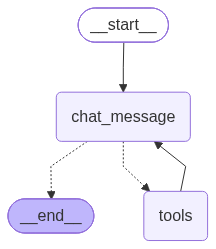

In [17]:
graph=StateGraph(ChatState)

graph.add_node("chat_message",chat_message)
graph.add_node("tools",toolnode)

graph.add_edge(START,"chat_message")
graph.add_conditional_edges("chat_message",tools_condition)
graph.add_edge("tools", "chat_message")  
workflow=graph.compile()
workflow

In [33]:
initial_state={
    "messages":[HumanMessage(content="What is 8989898*90909090+5404040?")]
}
final_state=workflow.invoke(initial_state)

In [34]:
final_state

{'messages': [HumanMessage(content='What is 8989898*90909090+5404040?', additional_kwargs={}, response_metadata={}, id='6b0c4f9c-241a-4f19-9260-8de3d3977e98'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "We need to compute expression: 8,989,898 * 90,909,090 + 5,404,040.\n\nLet's compute using calculator tool.", 'tool_calls': [{'id': 'fc_fec11558-d12a-4d0b-8eb2-d0afe17c840d', 'function': {'arguments': '{"expression":"8989898*90909090+5404040"}', 'name': 'calculator'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 71, 'prompt_tokens': 468, 'total_tokens': 539, 'completion_time': 0.152506286, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.024360699, 'prompt_tokens_details': None, 'queue_time': 0.347099394, 'total_time': 0.176866985}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4140daa9c2', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'},

In [35]:
print(final_state["messages"][-1].content)

The result of the calculation \(8989898 \times 90909090 + 5404040\) is **817,263,451,776,860**.


In [36]:
initial_state={
    "messages":[HumanMessage(content="what is the new movie releases in 2026")]
}
final_state=workflow.invoke(initial_state)
final_state

{'messages': [HumanMessage(content='what is the new movie releases in 2026', additional_kwargs={}, response_metadata={}, id='b57b049b-ded0-41a3-8f68-dc150b1c0a07'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "what is the new movie releases in 2026". They want a list of new movie releases in 2026. Need up-to-date info. Use search tool. Query: "2026 movie releases". Probably need list of upcoming movies scheduled for 2026. Use search.', 'tool_calls': [{'id': 'fc_2cd5295a-8cb7-49bf-a5f7-917da5eae7c9', 'function': {'arguments': '{"query":"2026 movie releases upcoming films 2026 release schedule","search_depth":"advanced","time_range":"year"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 118, 'prompt_tokens': 463, 'total_tokens': 581, 'completion_time': 0.247823044, 'completion_tokens_details': {'reasoning_tokens': 63}, 'prompt_time': 0.021658939, 'prompt_tokens_details': None, 'queue_time': 0.

In [38]:
final_state["messages"][-1].content

'Below is a snapshot of the most‑talked‑about movies slated to hit theaters (or major streaming platforms) in\u202f2026.\u202fThe titles are drawn from several industry‑wide round‑ups (Hollywood\u202fReporter,\u202fNo\u202fFilm\u202fSchool, Rolling\u202fStone, FirstShowing.net and IMDb’s release calendar) and represent a mix of blockbuster franchises, high‑profile sequels, and prestige‑picture debuts.\n\n---\n\n## 🎬 2026\u202fRelease Calendar (selected highlights)\n\n| Month | Title | Type / Franchise | Notable Talent / Director | Expected Release Window |\n|-------|-------|------------------|---------------------------|--------------------------|\n| **Jan** | **Dead\u202fMan’s\u202fWire** | Original | — | Jan\u202f9 |\n|  | **Primate** | Horror/Thriller | Johannes\u202fRoberts | Jan\u202f9 |\n|  | **The Rip** | Action/Thriller | Joe\u202fCarnahan | Jan\u202f16 |\n|  | **Send\u202fHelp** | Horror/Comedy | Sam\u202fRaimi | Jan\u202f30 |\n| **Feb** | **Wuthering\u202fHeights** | Literary

In [40]:
initial_state={
    "messages":[HumanMessage(content="First find out the stock price of Apple using get stock price tool then use the calculator tool to find out how much will it take to purchase 50 shares?")]
}
final_state=workflow.invoke(initial_state)
final_state["messages"][-1].content

'The current price of Apple (AAPL) is **$333.69** per share.  \n\nTo buy **50 shares**:\n\n\\[\n333.69 \\times 50 = \\mathbf{\\$16,684.50}\n\\]\n\nSo, purchasing 50 shares of Apple would cost **$16,684.50**.'

In [41]:
final_state

{'messages': [HumanMessage(content='First find out the stock price of Apple using get stock price tool then use the calculator tool to find out how much will it take to purchase 50 shares?', additional_kwargs={}, response_metadata={}, id='a146de0a-5d0c-4931-a0f9-dff060ef64f7'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "We need to call get_stock_price for Apple (AAPL), then use calculator to multiply price by 50. We'll need to extract price from result. Let's call function.", 'tool_calls': [{'id': 'fc_70a2be7e-9bfc-4e96-b7f2-6454b3e1df8a', 'function': {'arguments': '{"company":"AAPL"}', 'name': 'get_stock_price'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 65, 'prompt_tokens': 485, 'total_tokens': 550, 'completion_time': 0.137626113, 'completion_tokens_details': {'reasoning_tokens': 36}, 'prompt_time': 0.021366962, 'prompt_tokens_details': None, 'queue_time': 0.348673242, 'total_time': 0.158993075}, 'model_name': 'openai/gpt-oss

In [42]:
out = workflow.invoke({"messages": [HumanMessage(content="What is the current weather in New York?")]})
print(out["messages"][-1].content)

Here’s the latest weather for **New York, NY, USA**:

- **Condition:** Overcast clouds  
- **Temperature:** 16.3 °C (about 61 °F)  
- **Feels like:** 15.9 °C (60 °F)  
- **Humidity:** 73 %  
- **Pressure:** 1,024 hPa  
- **Wind:** 2.4 m/s (≈ 5.4 mph) from the direction indicated by local reports  
- **Visibility:** 10 km (≈ 6 mi)

Feel free to let me know if you need a forecast for the next few days or any other details!


In [18]:
result = workflow.invoke({"messages": [HumanMessage(content="Using the pdf notes, explain about transformer in a concise way")]})

print(result["messages"][-1].content)

[{'type': 'text', 'text': "Based on the provided PDF notes, here is a concise explanation of the **Transformer**:\n\n### 1. Core Concept\nThe Transformer is a model architecture designed for sequence-to-sequence tasks that completely **eschews recurrence** (recurrent neural networks). Instead, it **relies entirely on an attention mechanism** (specifically self-attention) to model global dependencies between inputs and outputs. \n\n### 2. Key Advantages\n* **Parallelization:** Unlike sequential models (like RNNs/LSTMs), it allows for significantly more parallel computation during training.\n* **Efficiency:** It achieves state-of-the-art translation quality with much faster training times (e.g., training in as little as 12 hours on 8 GPUs).\n* **Generalization:** It generalizes highly effectively to other tasks, such as English constituency parsing.\n\n### 3. Model Architecture\nThe Transformer uses an **Encoder-Decoder** structure:\n\n* **Encoder (Stack of $N = 6$ identical layers):**\n

In [19]:
print(result["messages"][-1].content[0]["text"])

Based on the provided PDF notes, here is a concise explanation of the **Transformer**:

### 1. Core Concept
The Transformer is a model architecture designed for sequence-to-sequence tasks that completely **eschews recurrence** (recurrent neural networks). Instead, it **relies entirely on an attention mechanism** (specifically self-attention) to model global dependencies between inputs and outputs. 

### 2. Key Advantages
* **Parallelization:** Unlike sequential models (like RNNs/LSTMs), it allows for significantly more parallel computation during training.
* **Efficiency:** It achieves state-of-the-art translation quality with much faster training times (e.g., training in as little as 12 hours on 8 GPUs).
* **Generalization:** It generalizes highly effectively to other tasks, such as English constituency parsing.

### 3. Model Architecture
The Transformer uses an **Encoder-Decoder** structure:

* **Encoder (Stack of $N = 6$ identical layers):**
  * Each layer contains two sub-layers:
 